In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import geopandas as gpd

from wildfire_stats import config as cfg
from wildfire_stats.data import classification as dcls
from wildfire_stats.data import io as dio
from wildfire_stats.data import rasters as drast
from wildfire_stats.fitting import fits as fits
from wildfire_stats.plotting import distributions as pdist
from wildfire_stats.plotting import landcover as plc
from wildfire_stats.reporting import summaries as rsum

P = cfg.load_paths()
MIN_FIRE_SIZE = 6.45  # km²; minimum fire size. Set to 4 to reproduce the earlier analysis
cfg.set_overrides(min_fire=MIN_FIRE_SIZE)  # every library default (xmin, amin_min, ...) follows this
A = cfg.load_assumptions()  # A["min_fire"] == MIN_FIRE_SIZE
MF_TAG = dio.minfire_tag()  # filename tag, e.g. "minfire6p45"
# must match the MIN_FIRE_SIZE of the notebook-5 run read below

# MTBS subset: "conus", "ak", or "all" (CONUS + AK; HI/PR always excluded)
MTBS_REGION = A["mtbs_region"]
MTBS_TAG = dio.mtbs_tag(MTBS_REGION)  # output filename prefix, e.g. mtbs_all

# EVT data year suffix (i.e., the XX in 20XX)
YR_SUFFIX = 25  # analyze 2025 EVT classifier

In [5]:
# SLOW; the static rasters are saved to P.logged_output / "static_evt".
# The original author never ran this to completion ("may have bugs") and used the
# 2024 rasters alone for the rest of the notebook.
# P.evt should contain every folder downloaded from LANDFIRE (CONUS and Alaska).
paths = drast.build_static_evt_us_auto(P.evt)
print(paths["us"])

KeyboardInterrupt: 

In [8]:
# written by notebook 5 (see the TODO there: this is df_refined, not the full fire table)
mtbs_gdf = dio.restore_truncated_columns(gpd.read_file(P.logged_output / f"{MTBS_TAG}_2003_2016_classified_timevarying_{MF_TAG}.shp"))
# guard against a file written before the mtbs_max_year cap
mtbs_gdf = dio.cap_mtbs_years(mtbs_gdf, "year")

mtbs_gdf.head()

,FIRE_ID,FIRE_NAME,year,STARTMONTH,STARTDAY,FIRE_TYPE,ACRES,IRWINID,MAP_ID,MAP_PROG,...,MODERATE_T,HIGH_THRES,COMMENTS,LATITUDE,LONGITUDE,SHAPE_AREA,SHAPE_LEN,area_km2,modis_clas,geometry
0,WA4612512155020120909,CASCADE CREEK,2012,9,9,Wildfire,20642.0,None,735,MTBS,...,302,580,None,46.142185,-121.547399,0.009733,0.592949,83.589212,Evergreen Needleleaf forest,"POLYGON ((-11722444.792 5283728.595, -11722350..."
1,FL3095508685320120923,UNNAMED,2012,9,23,Prescribed Fire,1654.0,None,740,MTBS,...,315,580,None,30.958938,-86.850201,0.000633,0.125394,6.700489,Woody savannas,"POLYGON ((-8379297.744 3763562.779, -8379367.8..."
2,WA4576012151620120905,HIGHWAY 141,2012,9,5,Wildfire,2080.0,None,741,MTBS,...,317,600,None,45.767790,-121.507116,0.000974,0.188978,8.420656,Evergreen Needleleaf forest,"POLYGON ((-11722844.112 5248805.318, -11722906..."
3,NM3326710859220120509,WHITEWATER-BALDY,2012,5,16,Wildfire,307528.0,None,744,MTBS,...,251,475,Extended dry period-->no spring green-up. Used...,33.334547,-108.591387,0.120291,4.473753,1242.073999,Savannas,"POLYGON ((-10454470.008 4025824.602, -10454494..."
4,FL3097408696320120925,UNNAMED,2012,9,25,Prescribed Fire,1640.0,None,745,MTBS,...,315,580,None,30.973980,-86.971609,0.000627,0.121308,6.635764,Woody savannas,"POLYGON ((-8390419.214 3766934.138, -8390404.8..."


In [11]:
fires_with_evt = dcls.classify_with_evt(
    fires_gdf=mtbs_gdf,
    conus_raster_path=P.evt / f"20{YR_SUFFIX}" / "Tif" / f"LF20{YR_SUFFIX}_EVT_CONUS.tif",
    alaska_raster_path=P.evt / f"20{YR_SUFFIX}" / "Tif" / f"LF20{YR_SUFFIX}_EVT_AK.tif",
    column_name="EVT_class",
)

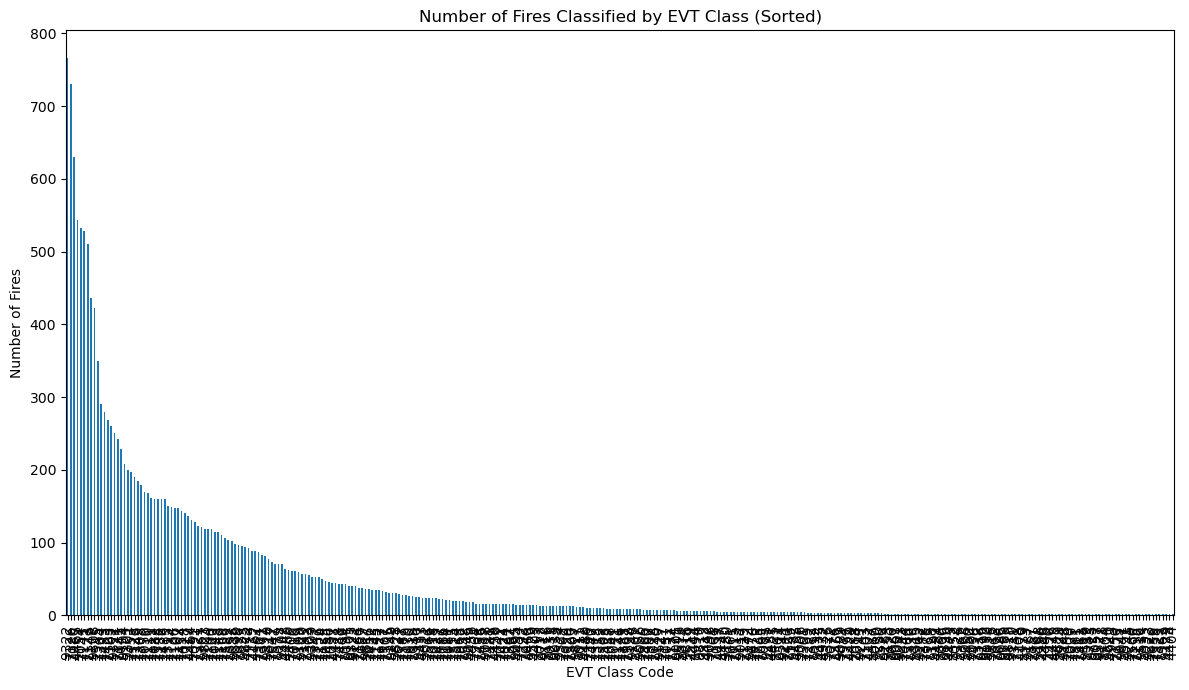

In [12]:
counts = plc.plot_category_counts(fires_with_evt, "EVT_class")

In [47]:
MIN_FIRES = 100  # toggle to try different configs

counts = fires_with_evt["EVT_class"].dropna().value_counts()
print(f"Number of EVT categories with >{A['min_fires']} fires: {(counts > MIN_FIRES).sum()}")

Number of EVT categories with >400 fires: 50


In [48]:
attribute_key = dio.load_evt_attributes(P.evt / '2025' / f"LF20{YR_SUFFIX}_EVT.csv")

mtbs = dio.attach_evt_attributes(fires_with_evt, attribute_key, code_col="EVT_class", key_col="VALUE")

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-category_facets_EVT-NAME_minfires100_minfire6p45.png


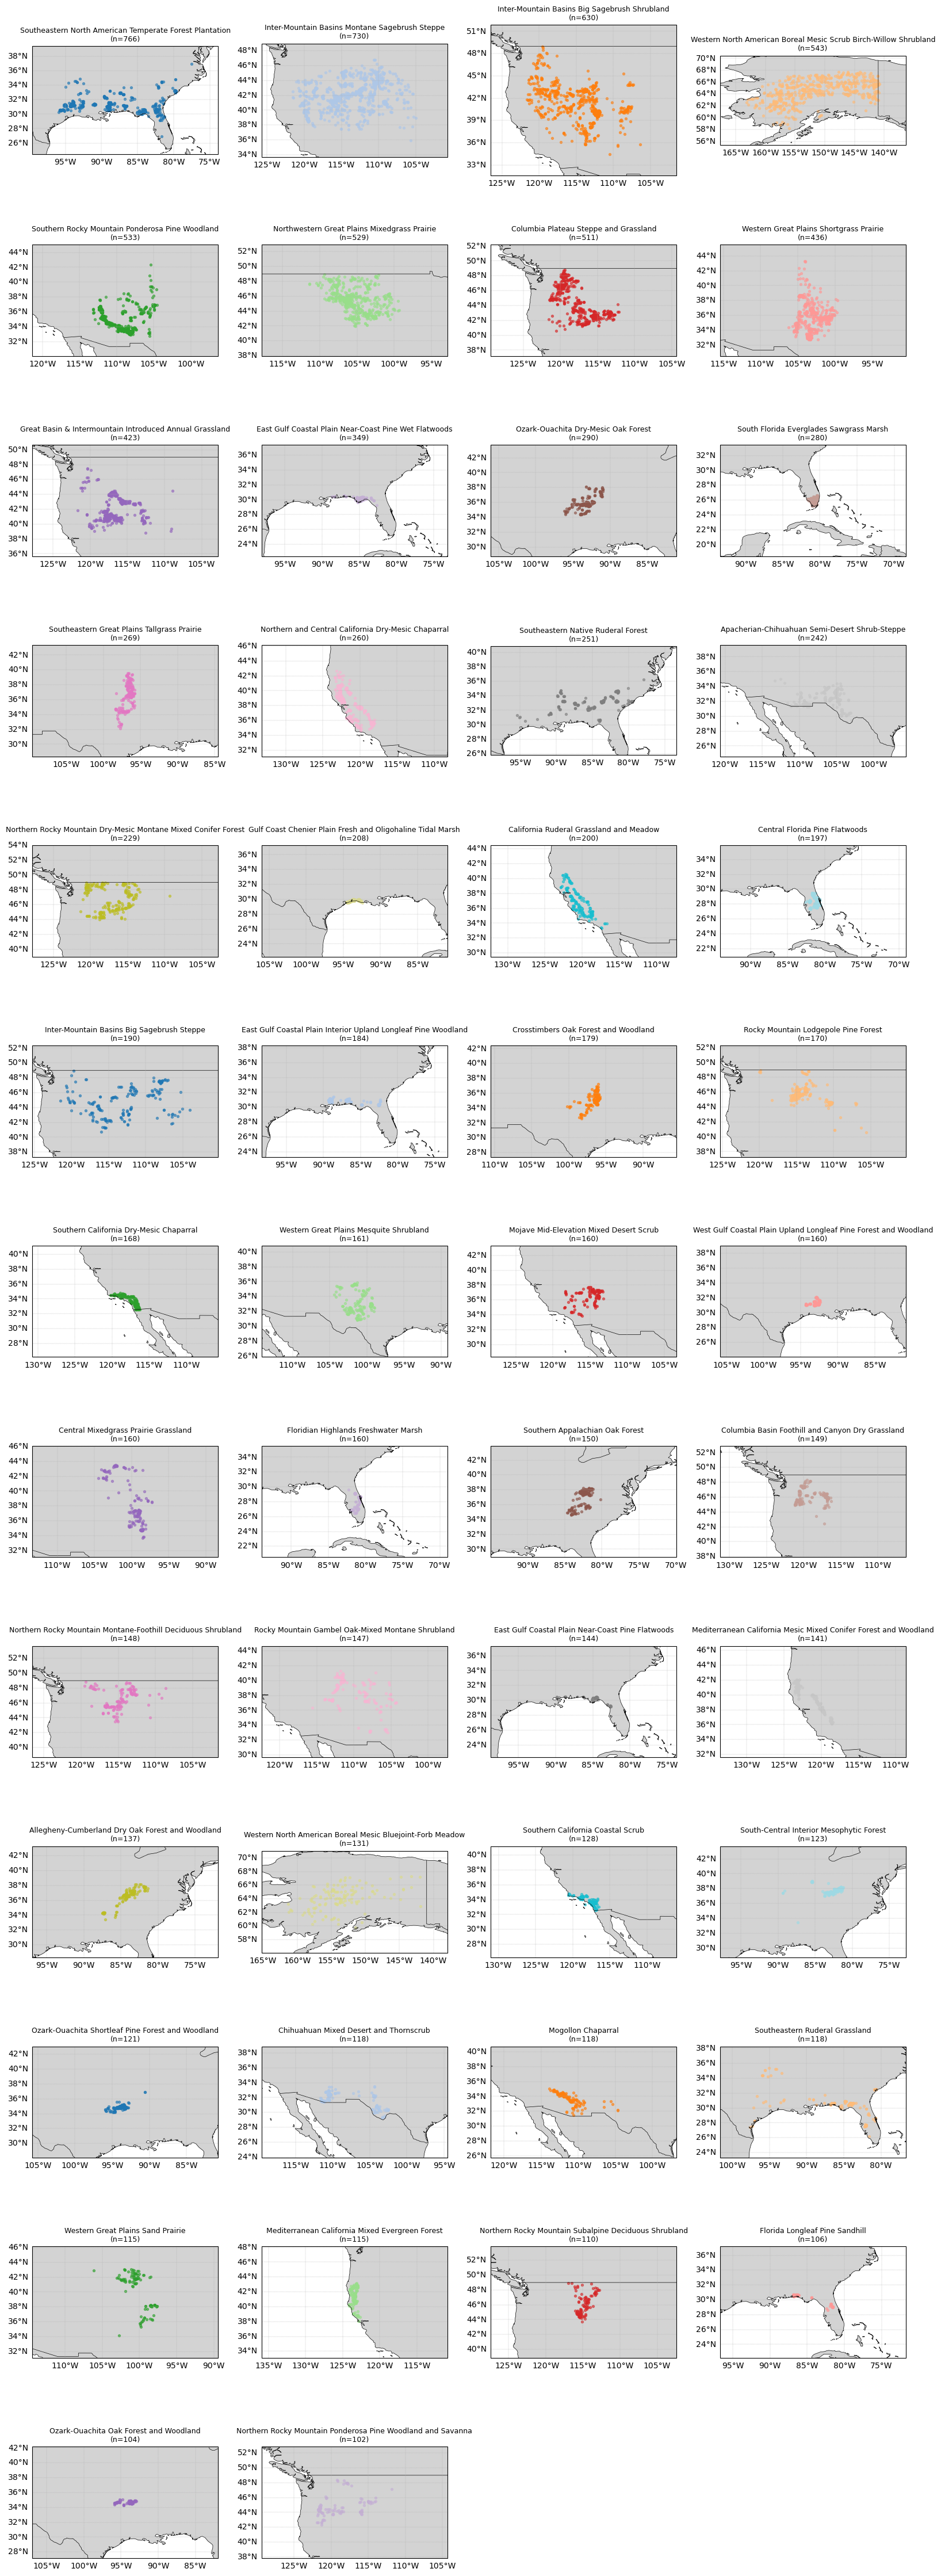

In [49]:
# ecological systems unit
plc.plot_category_facets(mtbs, col_name="EVT_NAME", min_fires=MIN_FIRES, save_figs=True)

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-category_facets_EVT-LF_minfires100_minfire6p45.png


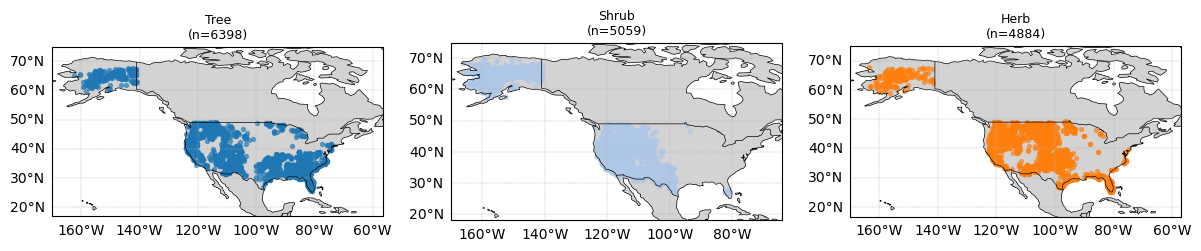

In [50]:
# vegetation lifeform
plc.plot_category_facets(mtbs, col_name="EVT_LF", min_fires=MIN_FIRES, save_figs=True)

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-category_facets_EVT-PHYS_minfires100_minfire6p45.png


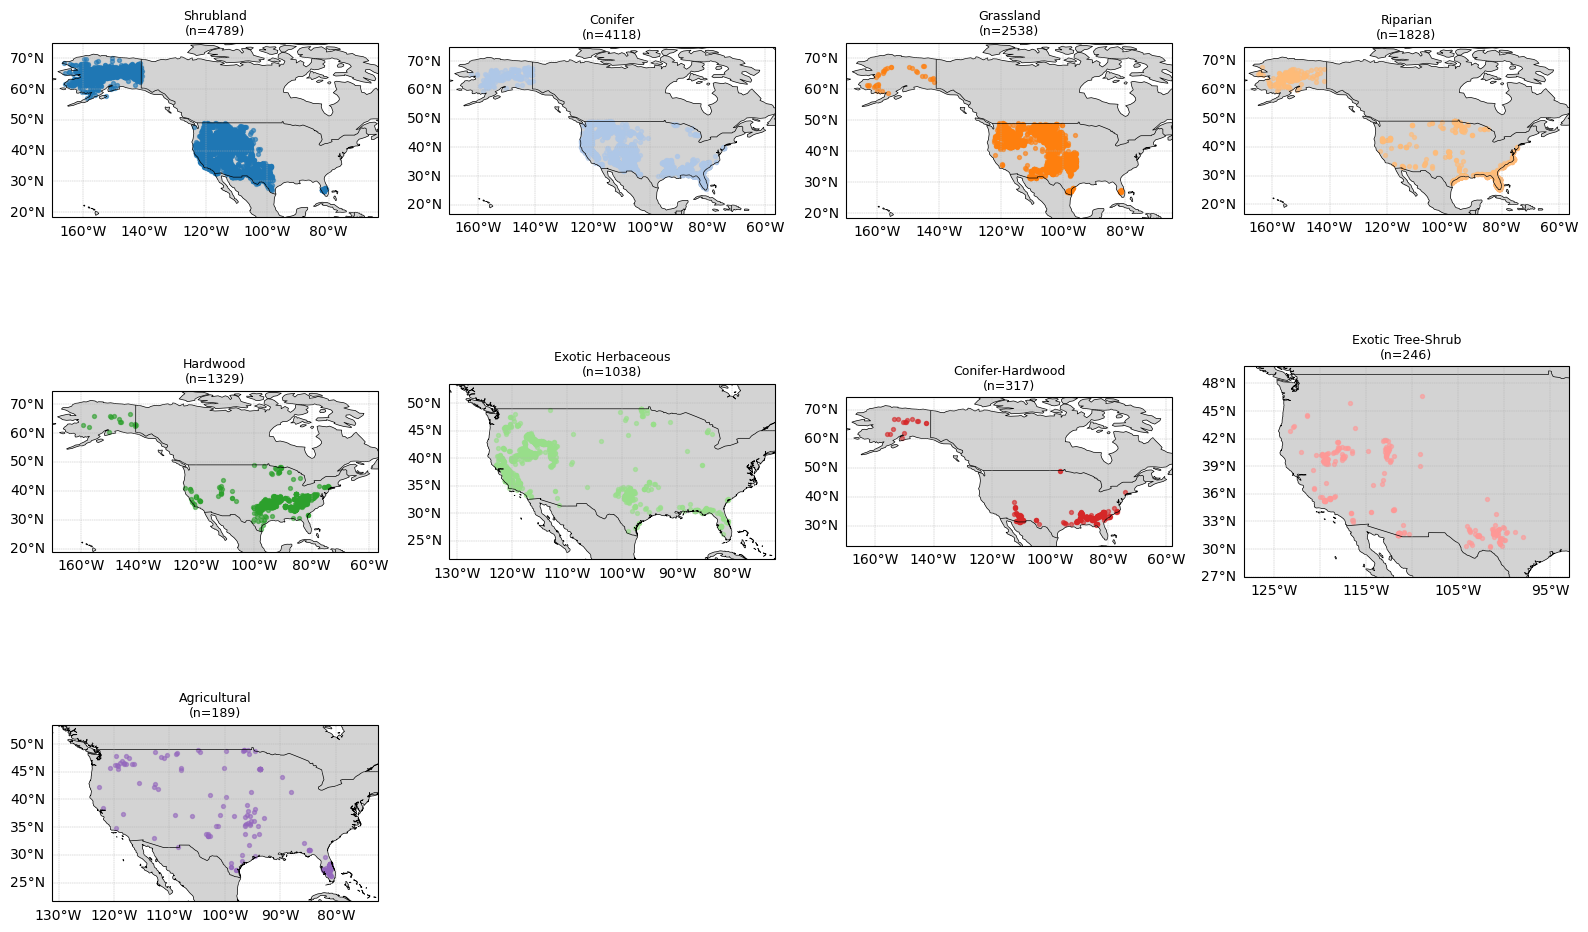

In [51]:
# Vegetation physiognomy
plc.plot_category_facets(mtbs, col_name="EVT_PHYS", min_fires=MIN_FIRES, save_figs=True)

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-category_facets_EVT-GP-N_minfires100_minfire6p45.png


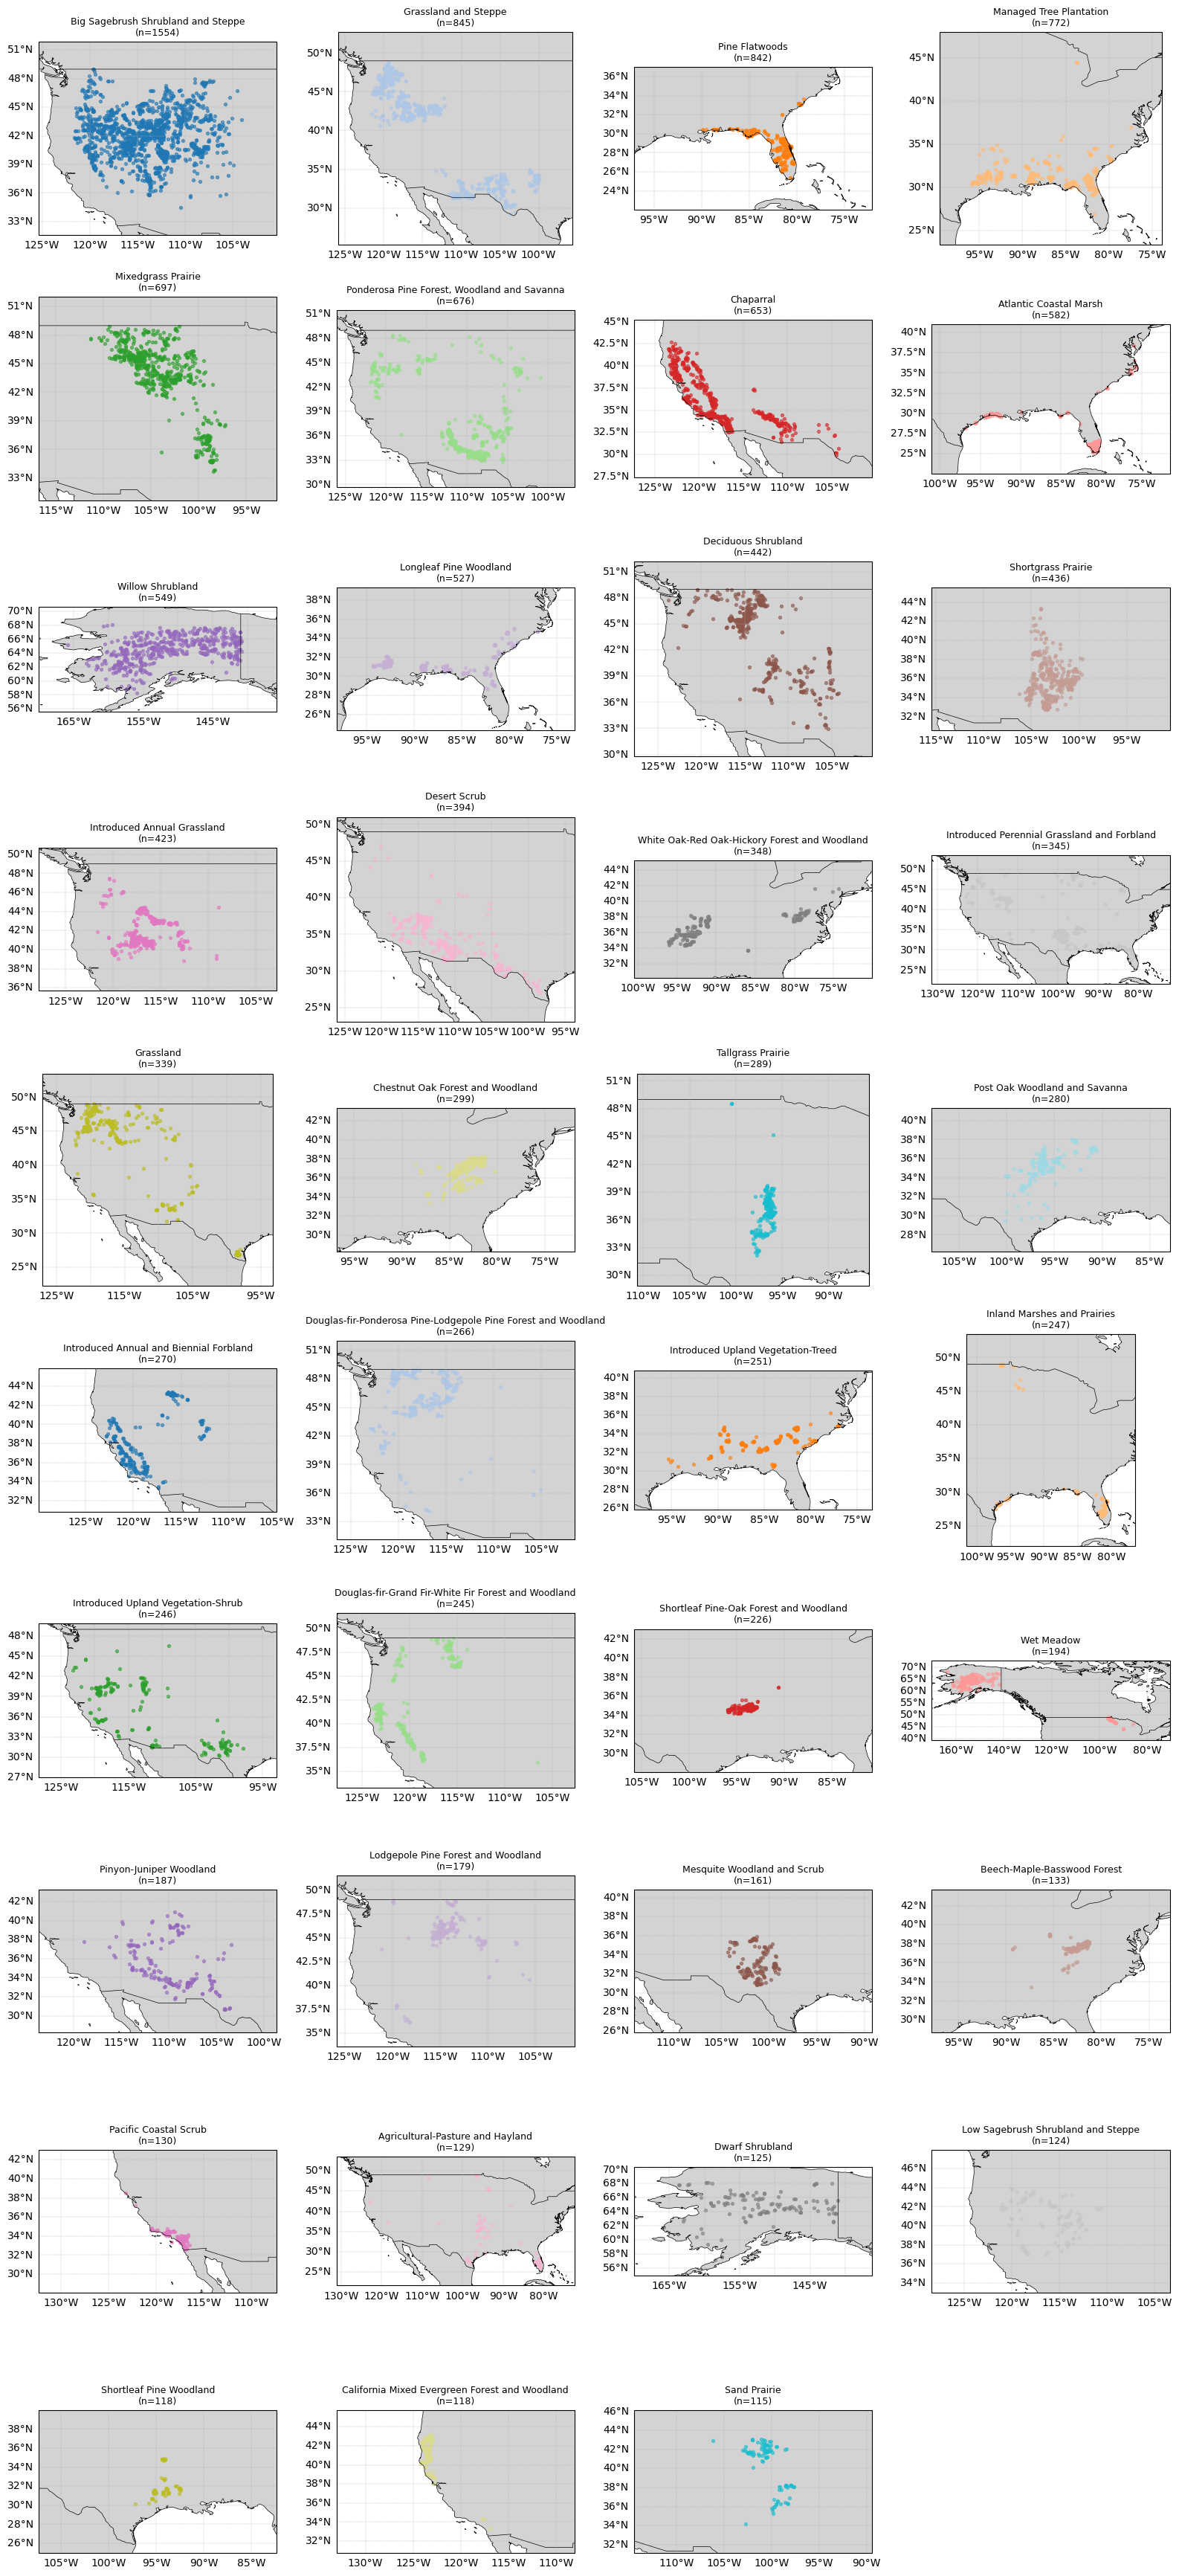

In [52]:
# Collapsed vegetation type
plc.plot_category_facets(mtbs, col_name="EVT_GP_N", min_fires=MIN_FIRES, save_figs=True)

In [25]:
# only fit EVT_NAME groups with >= min_fires fires total
overall_results_evt = fits.fit_static_by_group(mtbs, "EVT_NAME", min_n=A["min_fires"])

dio.save_pickle(overall_results_evt, P.output / f"{MTBS_TAG}_overall_results_evtname_{MF_TAG}.pkl")

⚠️ Skipping Alaska Arctic Mesic Alder Shrubland (only 1 fires)
⚠️ Skipping Alaska Arctic Permafrost Plateau Dwarf-Shrub Lichen Tundra (only 14 fires)
⚠️ Skipping Alaskan Pacific-Aleutian Alder-Salmonberry-Copperbush Shrubland (only 4 fires)
⚠️ Skipping Aleutian Ericaceous Dwarf-shrubland Heath and Fell-field (only 3 fires)
⚠️ Skipping Allegheny-Cumberland Dry Oak Forest and Woodland (only 137 fires)
⚠️ Skipping Apacherian-Chihuahuan Semi-Desert Grassland (only 52 fires)
⚠️ Skipping Apacherian-Chihuahuan Semi-Desert Shrub-Steppe (only 242 fires)
⚠️ Skipping Atlantic Coastal Plain Blackwater Stream Floodplain Forest (only 1 fires)
⚠️ Skipping Atlantic Coastal Plain Embayed Region Tidal Salt and Brackish Marsh (only 18 fires)
⚠️ Skipping Atlantic Coastal Plain Fall-line Sandhills Longleaf Pine Woodland (only 25 fires)
⚠️ Skipping Atlantic Coastal Plain Peatland Pocosin and Canebrake Woodland (only 35 fires)
⚠️ Skipping Atlantic Coastal Plain Small Blackwater River Floodplain Forest (only 

KeyboardInterrupt: 

In [ ]:
timevary_results_evt = fits.analyze_time_varying_mle(
    mtbs,
    overall_results_evt,
    group_col="EVT_NAME",
    restrict_to_fitted=True,
    R_boot=20,  # the original EVT run used the old default R_boot=20, not timevary_R_boot
)

In [ ]:
df_both_evt, df_p1_evt, df_p2_evt = rsum.summarize_timevary_modes(timevary_results_evt)
timevary_summary = rsum.summarize_fits(df_both_evt, df_p1_evt, df_p2_evt, overall_results_evt)
timevary_summary

The CCDF / CDF / Q–Q plotting function that was defined here is now `wildfire_stats.plotting.distributions.plot_group_ccdf_cdf_qq`.

In [ ]:
fig = pdist.plot_group_ccdf_cdf_qq(
    mtbs,
    "Apacherian-Chihuahuan Semi-Desert Shrub-Steppe",
    col_name="EVT_NAME",
    which=("weibull",),
    year_col="year",
    timevary_summary=timevary_summary,
    timevary_dist="weibull",
)

In [ ]:
overall_results_evt_collapsed = fits.fit_static_by_group(mtbs, "EVT_GP_N", min_n=A["min_fires"])

dio.save_pickle(overall_results_evt_collapsed, P.output / f"{MTBS_TAG}_overall_results_evtname_collapsed_{MF_TAG}.pkl")

In [ ]:
timevary_results_evt_collapsed = fits.analyze_time_varying_mle(
    mtbs,
    overall_results_evt_collapsed,
    group_col="EVT_GP_N",
    restrict_to_fitted=True,
    R_boot=20,  # the original EVT run used the old default R_boot=20, not timevary_R_boot
)

df_both_evt_collapsed, df_p1_evt_col, df_p2_evt_col = rsum.summarize_timevary_modes(timevary_results_evt_collapsed)
timevary_summary_col = rsum.summarize_fits(df_both_evt_collapsed, df_p1_evt_col, df_p2_evt_col, overall_results_evt_collapsed)
timevary_summary_col

In [ ]:
mtbs['EVT_NAME'].nunique()

In [ ]:
mtbs['EVT_GP_N'].nunique()